<a href="https://colab.research.google.com/github/hemrajmanikandan/hemrajmanikandan-Washing_Machine_Isolation_Forest/blob/main/washing_machine_isolation_forest.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:

from google.colab import drive
drive.mount('/content/drive')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:

import os

zip_path = "/content/drive/MyDrive/SMART-PDM-Dataset.zip"

if os.path.exists(zip_path):
    print("Dataset found!")
    print("File size:", round(os.path.getsize(zip_path) / (1024**3), 2), "GB")
else:
    print("ZIP file not found. Check its location in My Drive.")


Dataset found!
File size: 6.44 GB


In [ ]:

import zipfile

with zipfile.ZipFile(zip_path, "r") as z:
    names = z.namelist()

    print("Total files and folders:", len(names))
    print("\nFirst 30 entries:")
    for name in names[:30]:
        print(name)

    print("\nWashing-machine folder entries:")
    for name in names:
        if "2-washing_machines/" in name:
            print(name)
            if sum("2-washing_machines/" in x for x in names[:names.index(name)+1]) >= 30:
                break


Total files and folders: 4743

First 30 entries:
SMART-PDM-Dataset/
SMART-PDM-Dataset/1-code/
SMART-PDM-Dataset/1-code/extract_features.py
SMART-PDM-Dataset/1-code/filter_cycles_script.py
SMART-PDM-Dataset/1-code/pca.py
SMART-PDM-Dataset/2-washing_machines/
SMART-PDM-Dataset/2-washing_machines/2021-12-15_13.15.00_2021-12-15_16.15.00/
SMART-PDM-Dataset/2-washing_machines/2021-12-15_13.15.00_2021-12-15_16.15.00/fast.csv
SMART-PDM-Dataset/2-washing_machines/2021-12-15_13.15.00_2021-12-15_16.15.00/slow.csv
SMART-PDM-Dataset/2-washing_machines/2021-12-16_07.50.00_2021-12-16_10.38.00/
SMART-PDM-Dataset/2-washing_machines/2021-12-16_07.50.00_2021-12-16_10.38.00/fast.csv
SMART-PDM-Dataset/2-washing_machines/2021-12-16_07.50.00_2021-12-16_10.38.00/slow.csv
SMART-PDM-Dataset/2-washing_machines/2021-12-16_10.39.00_2021-12-16_13.22.00/
SMART-PDM-Dataset/2-washing_machines/2021-12-16_10.39.00_2021-12-16_13.22.00/fast.csv
SMART-PDM-Dataset/2-washing_machines/2021-12-16_10.39.00_2021-12-16_13.22.00/s

In [ ]:

import zipfile
import pandas as pd
from io import BytesIO

zip_path = "/content/drive/MyDrive/SMART-PDM-Dataset.zip"

with zipfile.ZipFile(zip_path, "r") as z:

    # Find CSV files inside the washing-machine folder
    csv_files = [
        name for name in z.namelist()
        if "SMART-PDM-Dataset/2-washing_machines/" in name
        and name.lower().endswith(".csv")
    ]

    print("Total washing-machine CSV files:", len(csv_files))

    print("\nFirst 10 CSV files:")
    for file in csv_files[:10]:
        print(file)

    # Read the first CSV file
    first_file = csv_files[0]

    with z.open(first_file) as f:
        sample_df = pd.read_csv(f)

print("\nSelected file:", first_file)
print("\nDataset shape:", sample_df.shape)

print("\nColumn names:")
print(sample_df.columns.tolist())

print("\nFirst five rows:")
display(sample_df.head())


Total washing-machine CSV files: 194

First 10 CSV files:
SMART-PDM-Dataset/2-washing_machines/2021-12-15_13.15.00_2021-12-15_16.15.00/fast.csv
SMART-PDM-Dataset/2-washing_machines/2021-12-15_13.15.00_2021-12-15_16.15.00/slow.csv
SMART-PDM-Dataset/2-washing_machines/2021-12-16_07.50.00_2021-12-16_10.38.00/fast.csv
SMART-PDM-Dataset/2-washing_machines/2021-12-16_07.50.00_2021-12-16_10.38.00/slow.csv
SMART-PDM-Dataset/2-washing_machines/2021-12-16_10.39.00_2021-12-16_13.22.00/fast.csv
SMART-PDM-Dataset/2-washing_machines/2021-12-16_10.39.00_2021-12-16_13.22.00/slow.csv
SMART-PDM-Dataset/2-washing_machines/2021-12-16_13.25.00_2021-12-16_16.10.00/fast.csv
SMART-PDM-Dataset/2-washing_machines/2021-12-16_13.25.00_2021-12-16_16.10.00/slow.csv
SMART-PDM-Dataset/2-washing_machines/2021-12-16_13.26.00_2021-12-16_16.10.00/fast.csv
SMART-PDM-Dataset/2-washing_machines/2021-12-16_13.26.00_2021-12-16_16.10.00/slow.csv

Selected file: SMART-PDM-Dataset/2-washing_machines/2021-12-15_13.15.00_2021-12-1

,UnixTimestamp (us),Current,Vibration
0,0,1846,1940
1,488,1847,1917
2,976,1851,1778
3,1464,1855,1791
4,1953,1856,1962


In [ ]:

import zipfile
import pandas as pd
import numpy as np

zip_path = "/content/drive/MyDrive/SMART-PDM-Dataset.zip"

with zipfile.ZipFile(zip_path, "r") as z:

    csv_files = [
        name for name in z.namelist()
        if "SMART-PDM-Dataset/2-washing_machines/" in name
        and name.lower().endswith(".csv")
    ]

    print("Total CSV files:", len(csv_files))

    for filename in csv_files[:6]:
        with z.open(filename) as f:
            temp = pd.read_csv(f)

        timestamps = temp["UnixTimestamp (µs)"]

        intervals = timestamps.diff().dropna()

        print("\nFile:", filename.split("/")[-1])
        print("Rows:", len(temp))
        print("Columns:", temp.columns.tolist())
        print("Average timestamp interval (µs):",
              round(intervals.mean(), 2))

        if intervals.mean() > 0:
            print("Estimated sampling rate (Hz):",
                  round(1_000_000 / intervals.mean(), 2))

        print("Missing values:")
        print(temp.isna().sum().to_dict())



File: fast.csv
Columns: ["'UnixTimestamp (us)'", "'Current'", "'Vibration'"]
Shape: (166000, 3)

File: slow.csv
Columns: ["'Ts'", "'ActE'", "'ActP'", "'RctP'", "'AppP'", "'Fr'", "'PF'", "'V'", "'A'"]
Shape: (9189, 9)

File: fast.csv
Columns: ["'UnixTimestamp (us)'", "'Current'", "'Vibration'"]
Shape: (102048, 3)

File: slow.csv
Columns: ["'Ts'", "'ActE'", "'ActP'", "'RctP'", "'AppP'", "'Fr'", "'PF'", "'V'", "'A'"]
Shape: (9513, 9)

File: fast.csv
Columns: ["'UnixTimestamp (us)'", "'Current'", "'Vibration'"]
Shape: (132000, 3)

File: slow.csv
Columns: ["'Ts'", "'ActE'", "'ActP'", "'RctP'", "'AppP'", "'Fr'", "'PF'", "'V'", "'A'"]
Shape: (8003, 9)

File: fast.csv
Columns: ["'UnixTimestamp (us)'", "'Current'", "'Vibration'"]
Shape: (20573000, 3)

File: slow.csv
Columns: ["'Ts'", "'ActE'", "'ActP'", "'RctP'", "'AppP'", "'Fr'", "'PF'", "'V'", "'A'"]
Shape: (9056, 9)

File: fast.csv
Columns: ["'UnixTimestamp (us)'", "'Current'", "'Vibration'"]
Shape: (89952, 3)

File: slow.csv
Columns: ["'Ts

In [ ]:

import zipfile
import pandas as pd
import numpy as np

zip_path = "/content/drive/MyDrive/SMART-PDM-Dataset.zip"

with zipfile.ZipFile(zip_path, "r") as z:

    fast_files = [
        name for name in z.namelist()
        if "2-washing_machines/" in name
        and name.endswith("/fast.csv")
    ]

    slow_files = [
        name for name in z.namelist()
        if "2-washing_machines/" in name
        and name.endswith("/slow.csv")
    ]

    print("Fast CSV files:", len(fast_files))
    print("Slow CSV files:", len(slow_files))

    # Read one fast CSV
    with z.open(fast_files[0]) as f:
        fast_df = pd.read_csv(f)

    # Remove unwanted quotation marks and spaces
    fast_df.columns = [
        str(c).strip().strip('"').strip("'").strip()
        for c in fast_df.columns
    ]

    print("\nCleaned fast CSV columns:")
    print(fast_df.columns.tolist())

    print("\nFirst five records:")
    display(fast_df.head())

    print("\nData types:")
    print(fast_df.dtypes)


Fast CSV files: 96
Slow CSV files: 96

Cleaned fast CSV columns:
['UnixTimestamp (us)', 'Current', 'Vibration']

First five records:


,UnixTimestamp (us),Current,Vibration
0,0,1846,1940
1,488,1847,1917
2,976,1851,1778
3,1464,1855,1791
4,1953,1856,1962



Data types:
UnixTimestamp (us)    int64
Current               int64
Vibration             int64
dtype: object


In [ ]:

# STEP 2: Calculate sampling rate

# Automatically find the timestamp column
timestamp_col = next(
    col for col in fast_df.columns
    if "timestamp" in col.lower()
)

# Convert timestamp to numeric
fast_df[timestamp_col] = pd.to_numeric(
    fast_df[timestamp_col],
    errors="coerce"
)

# Calculate time differences
time_difference = (
    fast_df[timestamp_col].diff().dropna()
)

# Remove invalid or zero intervals
time_difference = time_difference[
    time_difference > 0
]

median_interval = time_difference.median()

sampling_rate = 1_000_000 / median_interval

print("Timestamp column:", timestamp_col)
print("Median interval:", median_interval, "microseconds")
print("Estimated sampling rate:", round(sampling_rate, 2), "Hz")
print("Total readings:", len(fast_df))


Timestamp column: UnixTimestamp (us)
Median interval: 488.0 microseconds
Estimated sampling rate: 2049.18 Hz
Total readings: 166000


In [ ]:

with zipfile.ZipFile(zip_path, "r") as z:
    with z.open(slow_files[0]) as f:
        slow_df = pd.read_csv(f)

# Clean column names
slow_df.columns = [
    str(c).strip().strip('"').strip("'").strip()
    for c in slow_df.columns
]

print("Slow CSV columns:")
print(slow_df.columns.tolist())

print("\nDataset shape:", slow_df.shape)

display(slow_df.head())


Slow CSV columns:
['Ts', 'ActE', 'ActP', 'RctP', 'AppP', 'Fr', 'PF', 'V', 'A']

Dataset shape: (9189, 9)


,Ts,ActE,ActP,RctP,AppP,Fr,PF,V,A
0,1639574100,2413,0,-14,14,5001,50,23612,61
1,1639574101,2413,0,-14,14,5001,50,23607,61
2,1639574102,2413,0,-14,14,5000,51,23611,61
3,1639574103,2413,0,-14,14,5000,50,23610,61
4,1639574105,2413,0,-14,14,5000,51,23627,61


In [ ]:

# STEP 4: Inspect the slow sensor measurements

print("Slow dataset summary:")
display(slow_df.describe().round(2))

print("\nMissing values:")
display(slow_df.isnull().sum())

print("\nFirst and last timestamps:")
print("First:", slow_df["Ts"].iloc[0])
print("Last:", slow_df["Ts"].iloc[-1])

# Check timestamp intervals
slow_time = pd.to_numeric(slow_df["Ts"], errors="coerce")
print("\nTimestamp differences:")
print(slow_time.diff().value_counts().head(10))


Slow dataset summary:


,Ts,ActE,ActP,RctP,AppP,Fr,PF,V,A
count,9.189000e+03,9189.00,9189.00,9189.00,9189.00,9189.00,9189.00,9189.00,9189.00
mean,1.639579e+09,3261.92,419.10,152.46,538.42,4999.12,421.02,23391.26,2363.03
std,3.244480e+03,377.31,701.86,214.40,686.89,1.87,330.92,474.34,3049.45
min,1.639574e+09,2413.00,0.00,-15.00,13.00,4994.00,20.00,22139.00,59.00
25%,1.639577e+09,3167.00,3.00,-14.00,14.00,4998.00,218.00,23403.00,63.00
50%,1.639579e+09,3445.00,76.00,-5.00,313.00,4999.00,240.00,23570.00,1351.00
75%,1.639582e+09,3496.00,224.00,392.00,615.00,5000.00,687.00,23703.00,2595.00
max,1.639585e+09,3546.00,1919.00,775.00,2056.00,5007.00,1000.00,24044.00,8950.00



Missing values:


,0
Ts,0
ActE,0
ActP,0
RctP,0
AppP,0
Fr,0
PF,0
V,0
A,0



First and last timestamps:
First: 1639574100
Last: 1639584899

Timestamp differences:
Ts
1.0     6850
0.0     1612
2.0      445
3.0       96
4.0       39
5.0       27
6.0       16
7.0       12
8.0        8
17.0       7
Name: count, dtype: int64


In [ ]:

# STEP 6: Find dataset documentation

with zipfile.ZipFile(zip_path, "r") as z:

    all_names = z.namelist()

    docs = [
        name for name in all_names
        if name.lower().endswith(
            (".pdf", ".txt", ".md", ".json", ".yaml", ".yml")
        )
    ]

    print("Documentation files:", len(docs))

    for name in docs[:60]:
        print(name)


Documentation files: 0


In [ ]:

# Inspect the electrical measurements

electrical_cols = [
    "ActP", "RctP", "AppP", "Fr", "PF", "V", "A"
]

for col in electrical_cols:
    slow_df[col] = pd.to_numeric(
        slow_df[col], errors="coerce"
    )

print("Electrical measurement ranges:")

display(
    slow_df[electrical_cols]
    .describe()
    .T.round(2)
)

print("\nFirst 10 electrical readings:")
display(slow_df[electrical_cols].head(10))


Electrical measurement ranges:


,count,mean,std,min,25%,50%,75%,max
ActP,9189.0,419.10,701.86,0.0,3.0,76.0,224.0,1919.0
RctP,9189.0,152.46,214.40,-15.0,-14.0,-5.0,392.0,775.0
AppP,9189.0,538.42,686.89,13.0,14.0,313.0,615.0,2056.0
Fr,9189.0,4999.12,1.87,4994.0,4998.0,4999.0,5000.0,5007.0
PF,9189.0,421.02,330.92,20.0,218.0,240.0,687.0,1000.0
V,9189.0,23391.26,474.34,22139.0,23403.0,23570.0,23703.0,24044.0
A,9189.0,2363.03,3049.45,59.0,63.0,1351.0,2595.0,8950.0



First 10 electrical readings:


,ActP,RctP,AppP,Fr,PF,V,A
0,0,-14,14,5001,50,23612,61
1,0,-14,14,5001,50,23607,61
2,0,-14,14,5000,51,23611,61
3,0,-14,14,5000,50,23610,61
4,0,-14,14,5000,51,23627,61
5,0,-14,14,5000,51,23627,61
6,0,-14,14,5000,51,23633,61
7,0,-14,14,5000,50,23620,61
8,0,-14,14,5000,51,23623,61
9,0,-14,14,5000,51,23623,61


In [ ]:

# STEP 8: Inspect Python scripts inside the dataset ZIP

with zipfile.ZipFile(zip_path, "r") as z:

    py_files = [
        name for name in z.namelist()
        if name.lower().endswith(".py")
        and "1-code/" in name
    ]

    print("Python scripts found:")
    for name in py_files:
        print(name)

    # Display the first script
    if py_files:
        selected_script = py_files[0]

        print("\nInspecting:", selected_script)

        with z.open(selected_script) as f:
            script_text = f.read().decode(
                "utf-8", errors="replace"
            )

        print(script_text[:7000])


Python scripts found:
SMART-PDM-Dataset/1-code/extract_features.py
SMART-PDM-Dataset/1-code/filter_cycles_script.py
SMART-PDM-Dataset/1-code/pca.py

Inspecting: SMART-PDM-Dataset/1-code/extract_features.py
# -----------------------------------------------------------
# Script used for extracting features from time series data measured from home appliances 
#
# (C) 2022 Tiago Fonseca, Porto, Portugal
# This  work  was  supported  by  project SMART-PDM https://smart-pdm.eu/
# Released under GNU Public License (GPL)
# email calof@isep.ipp.pt
# -----------------------------------------------------------

import pandas as pd
from tsfresh import extract_features
from tsfresh.feature_extraction.feature_calculators import set_property

#Features selected for extraction. Please take a look at https://tsfresh.readthedocs.io/en/latest/text/introduction.html documentation if you want to change extracted features
fc_parameters = { 
    "variance_larger_than_standard_deviation": None,
    "sum_value

In [ ]:

import zipfile

with zipfile.ZipFile(zip_path, "r") as z:

    script_path = (
        "SMART-PDM-Dataset/1-code/filter_cycles_script.py"
    )

    with z.open(script_path) as f:
        filter_script = f.read().decode(
            "utf-8", errors="replace"
        )

print("ORIGINAL FILTER CYCLES SCRIPT")
print("=" * 60)
print(filter_script[:12000])


ORIGINAL FILTER CYCLES SCRIPT
# -----------------------------------------------------------
# Script used for identifying the begin and end time of home appliances working cycles 
# Please contact the team to request raw files
#
# (C) 2022 Tiago Fonseca, Porto, Portugal
# This  work  was  supported  by  project SMART-PDM https://smart-pdm.eu/
# Released under GNU Public License (GPL)
# email calof@isep.ipp.pt
# -----------------------------------------------------------

import pandas as pd

MINIMUM_MARGIN = 720  # 12 minutes tiniest cycle

def identify_cycles_from_raw_slow_stream(df):
    """
    Identifies the begin and end times of cycles given a dataframe containing the raw slow stream

    :param df: the slow stream to identify the cycles of. A time series with two collums
    - "Ts" is the collum containing the datetime of the mearument
    - "ActP" is tthe collum with the actual measuremnt of Active Power
    :type df: pandas.dataframe
    ...
    :return: list with pairs of dat

In [ ]:

import zipfile

with zipfile.ZipFile(zip_path, "r") as z:

    script_path = "SMART-PDM-Dataset/1-code/pca.py"

    with z.open(script_path) as f:
        pca_script = f.read().decode(
            "utf-8", errors="replace"
        )

print("ORIGINAL PCA SCRIPT")
print("=" * 60)
print(pca_script[:12000])


ORIGINAL PCA SCRIPT
# -----------------------------------------------------------
# Script used for doing a PCA analysis to the features dataset
#
# (C) 2022 Tiago Fonseca, Porto, Portugal
# This  work  was  supported  by  project SMART-PDM https://smart-pdm.eu/
# Released under GNU Public License (GPL)
# email calof@isep.ipp.pt
# -----------------------------------------------------------

import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
import matplotlib as plt

file = "X.csv" #name of the features dataset file (either for fridges or for washing machines)
df = pd.read_csv(file, sep=",")
X_a = df.iloc[:, 1:-2] 
y = df.iloc[:, -1].values
features = X_a.columns
X = X_a.values

# Standardize the features
X = StandardScaler().fit_transform(X)

# Instantiate PCA
pca = PCA(n_components=2) # 2 Dimensions

# Fit PCA to features
principalComponents = pca.fit_transform(X)

# Create a new dataset from principal components 
df = pd.DataFra

In [ ]:

import zipfile
import pandas as pd

with zipfile.ZipFile(zip_path, "r") as z:

    sessions = {}

    for name in z.namelist():
        if "2-washing_machines/" not in name:
            continue

        if name.endswith("/fast.csv"):
            sessions.setdefault(
                name.rsplit("/", 1)[0], {}
            )["fast"] = name

        elif name.endswith("/slow.csv"):
            sessions.setdefault(
                name.rsplit("/", 1)[0], {}
            )["slow"] = name

    paired_sessions = {
        session: paths
        for session, paths in sessions.items()
        if "fast" in paths and "slow" in paths
    }

    print("Paired sessions:", len(paired_sessions))

    session_path, paths = next(iter(paired_sessions.items()))

    with z.open(paths["fast"]) as f:
        fast_sample = pd.read_csv(f)

    with z.open(paths["slow"]) as f:
        slow_sample = pd.read_csv(f)


# Clean column names
def clean_columns(df):
    df.columns = [
        str(c).strip().strip('"').strip("'").strip()
        for c in df.columns
    ]
    return df

fast_sample = clean_columns(fast_sample)
slow_sample = clean_columns(slow_sample)

print("\nFAST CSV columns:")
print(fast_sample.columns.tolist())

print("\nSLOW CSV columns:")
print(slow_sample.columns.tolist())

# Find timestamp columns automatically
fast_time_col = next(
    (c for c in fast_sample.columns
     if "timestamp" in c.lower()),
    None
)

slow_time_col = next(
    (c for c in slow_sample.columns
     if c.lower() == "ts"),
    None
)

if fast_time_col is None or slow_time_col is None:
    raise ValueError("Timestamp column not found. Check column names.")

fast_ts = pd.to_numeric(
    fast_sample[fast_time_col], errors="coerce"
)

slow_ts = pd.to_numeric(
    slow_sample[slow_time_col], errors="coerce"
)

print("\nSESSION:", session_path)

print("\nFAST DATA")
print("Timestamp column:", fast_time_col)
print("Rows:", len(fast_sample))
print("Start:", fast_ts.min())
print("End:", fast_ts.max())
print("Duration (seconds):",
      round((fast_ts.max() - fast_ts.min()) / 1_000_000, 2))

print("\nSLOW DATA")
print("Timestamp column:", slow_time_col)
print("Rows:", len(slow_sample))
print("Start:", slow_ts.min())
print("End:", slow_ts.max())
print("Duration (seconds):",
      round(slow_ts.max() - slow_ts.min(), 2))

print("\nActive power summary:")
display(slow_sample["ActP"].describe())


Paired sessions: 96

FAST CSV columns:
['UnixTimestamp (us)', 'Current', 'Vibration']

SLOW CSV columns:
['Ts', 'ActE', 'ActP', 'RctP', 'AppP', 'Fr', 'PF', 'V', 'A']

SESSION: SMART-PDM-Dataset/2-washing_machines/2021-12-15_13.15.00_2021-12-15_16.15.00

FAST DATA
Timestamp column: UnixTimestamp (us)
Rows: 166000
Start: 0
End: 81054199
Duration (seconds): 81.05

SLOW DATA
Timestamp column: Ts
Rows: 9189
Start: 1639574100
End: 1639584899
Duration (seconds): 10799

Active power summary:


,ActP
count,9189.000000
mean,419.095331
std,701.856664
min,0.000000
25%,3.000000
50%,76.000000
75%,224.000000
max,1919.000000


In [ ]:

# STEP 13: Compare durations of all 96 sessions

import zipfile
import pandas as pd
import numpy as np

session_results = []

with zipfile.ZipFile(zip_path, "r") as z:

    for session, paths in paired_sessions.items():

        with z.open(paths["fast"]) as f:
            fast = pd.read_csv(f)

        with z.open(paths["slow"]) as f:
            slow = pd.read_csv(f)

        fast.columns = [
            str(c).strip().strip('"').strip("'").strip()
            for c in fast.columns
        ]

        slow.columns = [
            str(c).strip().strip('"').strip("'").strip()
            for c in slow.columns
        ]

        fast_ts = pd.to_numeric(
            fast["UnixTimestamp (us)"],
            errors="coerce"
        ).dropna()

        slow_ts = pd.to_numeric(
            slow["Ts"],
            errors="coerce"
        ).dropna()

        fast_duration = (
            fast_ts.max() - fast_ts.min()
        ) / 1_000_000

        slow_duration = (
            slow_ts.max() - slow_ts.min()
        )

        session_results.append({
            "session": session.split("/")[-1],
            "fast_rows": len(fast),
            "slow_rows": len(slow),
            "fast_duration_sec": round(fast_duration, 2),
            "slow_duration_sec": round(slow_duration, 2),
            "duration_ratio": round(
                fast_duration / slow_duration, 4
            ) if slow_duration > 0 else np.nan
        })

duration_df = pd.DataFrame(session_results)

print("Total sessions:", len(duration_df))

print("\nDuration summary:")
display(
    duration_df[
        ["fast_duration_sec", "slow_duration_sec"]
    ].describe().round(2)
)

print("\nFirst 15 sessions:")
display(duration_df.head(15))

print("\nSessions with shortest fast recordings:")
display(
    duration_df.sort_values(
        "fast_duration_sec"
    ).head(10)
)


Total sessions: 96

Duration summary:


,fast_duration_sec,slow_duration_sec
count,95.00,96.00
mean,5292.48,5775.94
std,3468.15,3475.67
min,34.18,248.00
25%,3412.50,3212.75
50%,4775.00,4709.00
75%,7696.00,9897.50
max,15233.00,11999.00



First 15 sessions:


,session,fast_rows,slow_rows,fast_duration_sec,slow_duration_sec,duration_ratio
0,2021-12-15_13.15.00_2021-12-15_16.15.00,166000,9189,81.05,10799,0.0075
1,2021-12-16_07.50.00_2021-12-16_10.38.00,102048,9513,49.83,10079,0.0049
2,2021-12-16_10.39.00_2021-12-16_13.22.00,132000,8003,64.45,9779,0.0066
3,2021-12-16_13.25.00_2021-12-16_16.10.00,20573000,9056,9625.13,9899,0.9723
4,2021-12-16_13.26.00_2021-12-16_16.10.00,89952,8996,43.92,9839,0.0045
5,2021-12-17_08.30.00_2021-12-17_11.15.00,88000,9348,42.97,9897,0.0043
6,2021-12-17_08.30.00_2021-12-17_11.16.00,20995000,9411,9394.30,9959,0.9433
7,2021-12-20_07.55.00_2021-12-20_09.45.00,84000,6568,41.02,6599,0.0062
8,2021-12-20_10.00.00_2021-12-20_11.55.00,13203000,6868,5599.12,6899,0.8116
9,2021-12-20_10.00.00_2021-12-20_12.00.00,70000,7166,34.18,7198,0.0047



Sessions with shortest fast recordings:


,session,fast_rows,slow_rows,fast_duration_sec,slow_duration_sec,duration_ratio
9,2021-12-20_10.00.00_2021-12-20_12.00.00,70000,7166,34.18,7198,0.0047
11,2021-12-20_15.00.00_2021-12-20_16.50.00,82000,6529,40.04,6599,0.0061
7,2021-12-20_07.55.00_2021-12-20_09.45.00,84000,6568,41.02,6599,0.0062
5,2021-12-17_08.30.00_2021-12-17_11.15.00,88000,9348,42.97,9897,0.0043
4,2021-12-16_13.26.00_2021-12-16_16.10.00,89952,8996,43.92,9839,0.0045
10,2021-12-20_12.55.00_2021-12-20_14.40.00,90000,6243,43.94,6299,0.0070
1,2021-12-16_07.50.00_2021-12-16_10.38.00,102048,9513,49.83,10079,0.0049
13,2021-12-22_10.55.00_2021-12-22_12.40.00,110000,6171,53.71,6299,0.0085
12,2021-12-22_07.55.00_2021-12-22_09.40.00,112000,6000,54.69,6299,0.0087
2,2021-12-16_10.39.00_2021-12-16_13.22.00,132000,8003,64.45,9779,0.0066


In [ ]:

import zipfile
import pandas as pd
import numpy as np

zip_path = "/content/drive/MyDrive/SMART-PDM-Dataset.zip"

session_features = []

with zipfile.ZipFile(zip_path, "r") as z:

    slow_files = [
        name for name in z.namelist()
        if "2-washing_machines/" in name
        and name.endswith("/slow.csv")
    ]

    for file_path in slow_files:

        with z.open(file_path) as f:
            data = pd.read_csv(f)

        # Clean column names
        data.columns = [
            str(c).strip().strip('"').strip("'").strip()
            for c in data.columns
        ]

        # Convert measurements to numeric
        columns = [
            "ActP", "RctP", "AppP",
            "Fr", "PF", "V", "A"
        ]

        for col in columns:
            data[col] = pd.to_numeric(
                data[col], errors="coerce"
            )

        # Extract statistical features per session
        features = {}

        for col in columns:
            values = data[col].dropna()

            features[col + "_mean"] = values.mean()
            features[col + "_std"] = values.std()
            features[col + "_min"] = values.min()
            features[col + "_max"] = values.max()
            features[col + "_median"] = values.median()
            features[col + "_range"] = (
                values.max() - values.min()
            )

        features["session"] = file_path.split("/")[-2]

        session_features.append(features)

feature_df = pd.DataFrame(session_features)

print("Feature extraction completed!")
print("Total sessions:", len(feature_df))
print("Total features:", feature_df.shape[1] - 1)

display(feature_df.head())


Feature extraction completed!
Total sessions: 96
Total features: 42


,ActP_mean,ActP_std,ActP_min,ActP_max,ActP_median,ActP_range,RctP_mean,RctP_std,RctP_min,RctP_max,...,V_max,V_median,V_range,A_mean,A_std,A_min,A_max,A_median,A_range,session
0,419.095331,701.856664,0,1919,76.0,1919,152.462074,214.397546,-15,775,...,24044,23570.0,1905,2363.030254,3049.445853,59,8950,1351.0,8891,2021-12-15_13.15.00_2021-12-15_16.15.00
1,510.303585,750.006117,0,1933,109.0,1933,160.407548,211.717858,-15,771,...,23861,23447.0,1793,2772.220015,3219.542035,58,8822,1655.0,8764,2021-12-16_07.50.00_2021-12-16_10.38.00
2,565.154317,765.009645,0,1871,106.0,1871,165.906285,209.781734,-14,760,...,23526,23134.0,1518,3037.956766,3270.831287,58,8832,1854.0,8774,2021-12-16_10.39.00_2021-12-16_13.22.00
3,460.924691,717.411514,0,1934,103.0,1934,162.295384,209.410881,-15,781,...,23755,23268.0,1725,2589.092425,3108.349899,59,8944,1595.0,8885,2021-12-16_13.25.00_2021-12-16_16.10.00
4,463.998888,718.808597,0,1934,103.0,1934,163.471209,209.610911,-15,781,...,23755,23269.0,1725,2605.960538,3111.806040,59,8944,1603.0,8885,2021-12-16_13.26.00_2021-12-16_16.10.00


In [ ]:

print("Dataset shape:", feature_df.shape)

print("\nMissing values:")
print(feature_df.isnull().sum().sum())

print("\nFeature statistics:")
display(feature_df.describe().round(3))

print("\nSession names:")
display(feature_df[["session"]].head(10))


Dataset shape: (96, 43)

Missing values:
0

Feature statistics:


,ActP_mean,ActP_std,ActP_min,ActP_max,ActP_median,ActP_range,RctP_mean,RctP_std,RctP_min,RctP_max,...,V_min,V_max,V_median,V_range,A_mean,A_std,A_min,A_max,A_median,A_range
count,96.000,96.000,96.000,96.000,96.000,96.000,96.000,96.000,96.000,96.000,...,96.000,96.000,96.000,96.000,96.000,96.000,96.000,96.000,96.000,96.000
mean,383.900,491.731,0.646,1402.583,235.479,1401.938,74.932,105.785,-18.833,351.365,...,21957.083,23744.219,23379.240,1787.135,1994.216,2189.505,66.896,6675.927,1513.328,6609.031
std,365.671,354.094,1.641,875.515,516.206,875.477,139.734,154.479,5.063,498.705,...,3258.579,182.750,243.839,3262.682,1728.456,1512.337,23.062,4042.537,2317.698,4045.367
min,0.000,0.000,0.000,0.000,0.000,0.000,-27.985,0.000,-33.000,-27.000,...,0.000,23235.000,22717.000,212.000,52.531,0.073,0.000,53.000,52.000,1.000
25%,45.029,68.654,0.000,309.000,9.000,309.000,-13.821,7.206,-18.000,15.750,...,22059.750,23655.500,23268.750,931.500,304.902,428.862,58.000,2006.000,133.000,1955.000
50%,373.355,643.858,0.000,1792.500,51.500,1792.500,-3.039,21.443,-17.500,85.000,...,22430.000,23750.000,23417.000,1411.500,1769.670,2757.138,64.000,7784.500,349.500,7718.000
75%,585.326,776.632,0.000,2053.500,166.250,2053.500,159.733,209.654,-15.000,766.750,...,22857.500,23866.000,23543.750,1725.000,3081.077,3371.398,67.000,9334.250,1872.500,9202.000
max,1549.423,998.132,8.000,2286.000,1967.000,2286.000,467.172,453.902,-13.000,1453.000,...,23520.000,24100.000,23851.000,23775.000,6861.706,4306.575,133.000,12243.000,8675.000,12184.000



Session names:


,session
0,2021-12-15_13.15.00_2021-12-15_16.15.00
1,2021-12-16_07.50.00_2021-12-16_10.38.00
2,2021-12-16_10.39.00_2021-12-16_13.22.00
3,2021-12-16_13.25.00_2021-12-16_16.10.00
4,2021-12-16_13.26.00_2021-12-16_16.10.00
5,2021-12-17_08.30.00_2021-12-17_11.15.00
6,2021-12-17_08.30.00_2021-12-17_11.16.00
7,2021-12-20_07.55.00_2021-12-20_09.45.00
8,2021-12-20_10.00.00_2021-12-20_11.55.00
9,2021-12-20_10.00.00_2021-12-20_12.00.00


In [ ]:

# STEP 3: Train washing-machine anomaly detector

import numpy as np
import pandas as pd
import joblib

from sklearn.ensemble import IsolationForest
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

# Select only the original 42 numerical features
features = [
    col for col in feature_df.columns
    if col != "session"
    and pd.api.types.is_numeric_dtype(feature_df[col])
]

X = feature_df[features].copy()

# Replace infinite values
X = X.replace([np.inf, -np.inf], np.nan)

print("Selected features:", len(features))
print("Dataset shape:", X.shape)
print("Non-numeric columns excluded:",
      [c for c in feature_df.columns
       if c not in features and c != "session"])

# Create model pipeline
model_a = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("detector", IsolationForest(
        n_estimators=300,
        contamination="auto",
        random_state=42
    ))
])

# Train model
model_a.fit(X)

# Calculate anomaly scores
scores = model_a.decision_function(X)

# Predict
predictions = model_a.predict(X)

# Store results
results = feature_df[["session"]].copy()

results["anomaly_score"] = scores

results["prediction"] = np.where(
    predictions == -1,
    "Anomaly",
    "Normal-looking"
)

print("\nMODEL A TRAINING COMPLETED!")

print("\nPrediction counts:")
print(results["prediction"].value_counts())

print("\nFirst 15 predictions:")
display(results.head(15))


Selected features: 42
Dataset shape: (96, 42)
Non-numeric columns excluded: []

MODEL A TRAINING COMPLETED!

Prediction counts:
prediction
Normal-looking    72
Anomaly           24
Name: count, dtype: int64

First 15 predictions:


,session,anomaly_score,prediction
0,2021-12-15_13.15.00_2021-12-15_16.15.00,0.062569,Normal-looking
1,2021-12-16_07.50.00_2021-12-16_10.38.00,0.087732,Normal-looking
2,2021-12-16_10.39.00_2021-12-16_13.22.00,0.078046,Normal-looking
3,2021-12-16_13.25.00_2021-12-16_16.10.00,0.094062,Normal-looking
4,2021-12-16_13.26.00_2021-12-16_16.10.00,0.093924,Normal-looking
5,2021-12-17_08.30.00_2021-12-17_11.15.00,0.086088,Normal-looking
6,2021-12-17_08.30.00_2021-12-17_11.16.00,0.085741,Normal-looking
7,2021-12-20_07.55.00_2021-12-20_09.45.00,0.035627,Normal-looking
8,2021-12-20_10.00.00_2021-12-20_11.55.00,0.037115,Normal-looking
9,2021-12-20_10.00.00_2021-12-20_12.00.00,0.041049,Normal-looking


In [ ]:

ranked_results = results.sort_values(
    by="anomaly_score",
    ascending=True
)

print("10 MOST UNUSUAL SESSIONS:")
display(ranked_results.head(10))

print("\n10 MOST NORMAL-LOOKING SESSIONS:")
display(ranked_results.tail(10))


10 MOST UNUSUAL SESSIONS:


,session,anomaly_score,prediction
26,2022-02-25_11.25.00_2022-02-25_14.15.00,-0.092673,Anomaly
89,2022-07-07_09.09.00_2022-07-07_10.10.00,-0.092501,Anomaly
27,2022-02-25_11.25.00_2022-02-25_14.20.00,-0.090730,Anomaly
80,2022-06-23_07.43.00_2022-06-23_09.27.00,-0.071021,Anomaly
12,2021-12-22_07.55.00_2021-12-22_09.40.00,-0.062706,Anomaly
76,2022-06-22_06.44.00_2022-06-22_08.55.00,-0.055104,Anomaly
56,2022-04-06_07.15.00_2022-04-06_09.10.00,-0.054653,Anomaly
53,2022-04-05_07.14.00_2022-04-05_08.50.00,-0.048531,Anomaly
81,2022-06-23_07.45.00_2022-06-23_09.49.00,-0.044059,Anomaly
93,2022-07-08_07.26.00_2022-07-08_08.30.00,-0.043464,Anomaly



10 MOST NORMAL-LOOKING SESSIONS:


,session,anomaly_score,prediction
64,2022-05-05_07.35.00_2022-05-05_10.30.00,0.090707,Normal-looking
61,2022-05-03_13.29.00_2022-05-03_15.40.00,0.092194,Normal-looking
4,2021-12-16_13.26.00_2021-12-16_16.10.00,0.093924,Normal-looking
3,2021-12-16_13.25.00_2021-12-16_16.10.00,0.094062,Normal-looking
31,2022-03-21_13.04.00_2022-03-21_14.04.00,0.097938,Normal-looking
32,2022-03-21_13.04.00_2022-03-21_14.05.00,0.098570,Normal-looking
63,2022-05-04_10.06.00_2022-05-04_13.10.00,0.098626,Normal-looking
33,2022-03-21_14.20.00_2022-03-21_15.20.00,0.099026,Normal-looking
30,2022-03-21_10.50.00_2022-03-21_11.52.00,0.103742,Normal-looking
60,2022-05-03_09.00.00_2022-05-03_12.12.00,0.110077,Normal-looking


In [ ]:

# STEP 5: Identify features associated with anomalies

# Separate normal-looking and anomalous sessions
normal_data = X.loc[
    results["prediction"] == "Normal-looking"
]

anomaly_data = X.loc[
    results["prediction"] == "Anomaly"
]

# Compare median feature values
normal_median = normal_data.median()
anomaly_median = anomaly_data.median()

comparison = pd.DataFrame({
    "feature": features,
    "normal_median": normal_median.values,
    "anomaly_median": anomaly_median.values
})

comparison["absolute_difference"] = (
    comparison["anomaly_median"] -
    comparison["normal_median"]
).abs()

comparison = comparison.sort_values(
    "absolute_difference",
    ascending=False
)

print("TOP 15 FEATURES DIFFERING IN ANOMALOUS SESSIONS")

display(comparison.head(15).round(3))


TOP 15 FEATURES DIFFERING IN ANOMALOUS SESSIONS


,feature,normal_median,anomaly_median,absolute_difference
40,A_median,328.500,3187.000,2858.500
36,A_mean,1580.903,3993.689,2412.786
39,A_max,7769.000,9199.000,1430.000
41,A_range,7704.000,9101.500,1397.500
37,A_std,2689.580,3706.471,1016.892
16,AppP_median,77.000,753.500,676.500
12,AppP_mean,360.714,916.532,555.819
0,ActP_mean,340.154,765.835,425.681
35,V_range,1513.500,1210.000,303.500
15,AppP_max,1786.000,2081.500,295.500


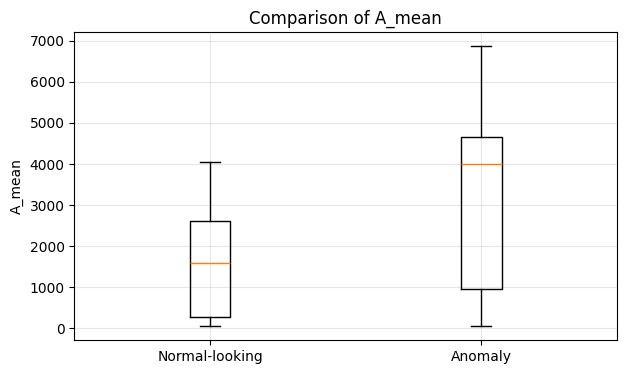

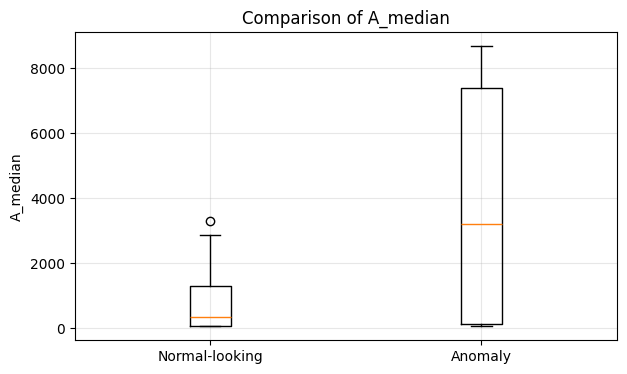

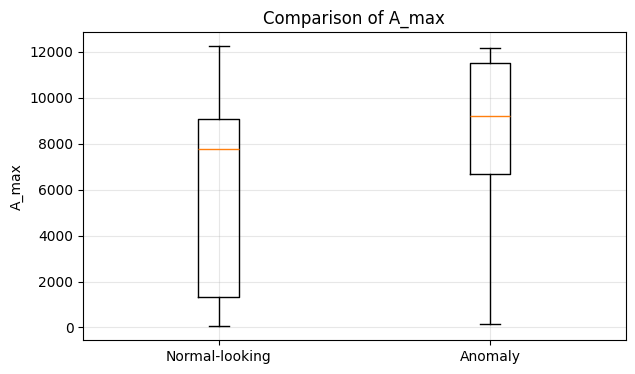

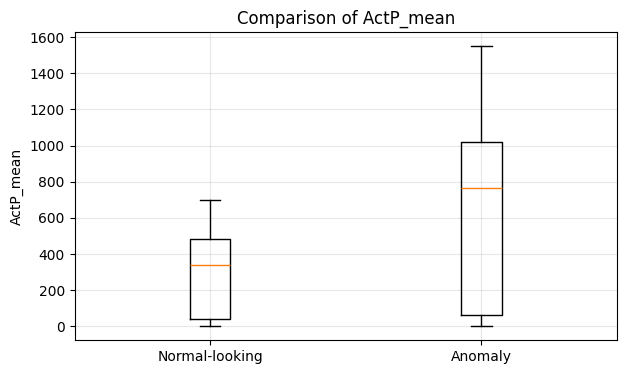

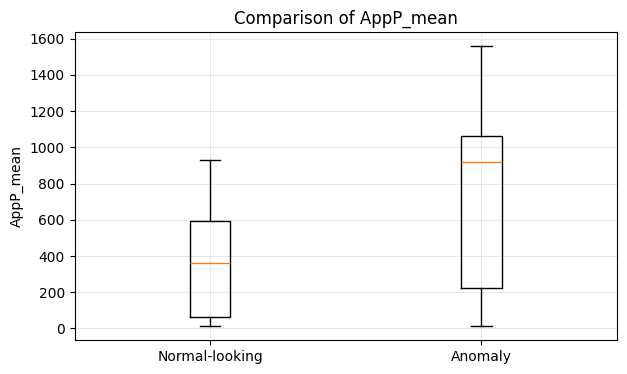

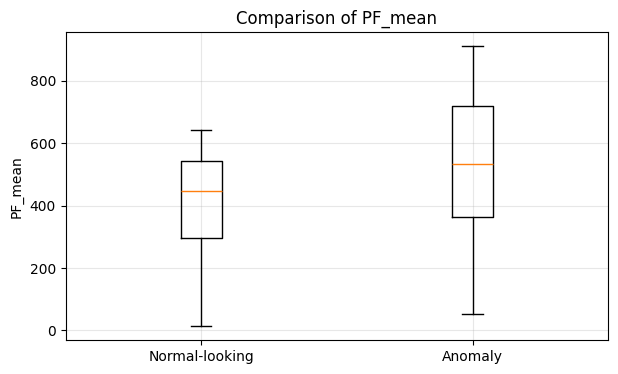

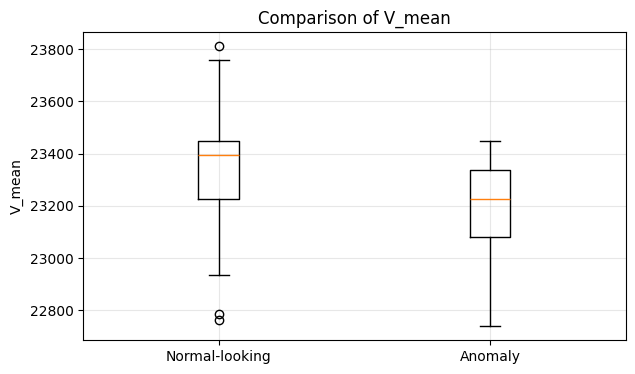

In [ ]:

import matplotlib.pyplot as plt

# Compare important electrical features
important_features = [
    "A_mean",
    "A_median",
    "A_max",
    "ActP_mean",
    "AppP_mean",
    "PF_mean",
    "V_mean"
]

for col in important_features:

    plt.figure(figsize=(7, 4))

    plt.boxplot(
        [
            X.loc[results["prediction"] == "Normal-looking", col],
            X.loc[results["prediction"] == "Anomaly", col]
        ],
        tick_labels=["Normal-looking", "Anomaly"]
    )

    plt.title(f"Comparison of {col}")
    plt.ylabel(col)
    plt.grid(alpha=0.3)
    plt.show()


In [ ]:

# Display all anomalous sessions

anomalous_sessions = results[
    results["prediction"] == "Anomaly"
].copy()

print("Total anomalous sessions:",
      len(anomalous_sessions))

display(
    anomalous_sessions.sort_values(
        "anomaly_score"
    ).reset_index(drop=True)
)


Total anomalous sessions: 24


,session,anomaly_score,prediction
0,2022-02-25_11.25.00_2022-02-25_14.15.00,-0.092673,Anomaly
1,2022-07-07_09.09.00_2022-07-07_10.10.00,-0.092501,Anomaly
2,2022-02-25_11.25.00_2022-02-25_14.20.00,-0.090730,Anomaly
3,2022-06-23_07.43.00_2022-06-23_09.27.00,-0.071021,Anomaly
4,2021-12-22_07.55.00_2021-12-22_09.40.00,-0.062706,Anomaly
5,2022-06-22_06.44.00_2022-06-22_08.55.00,-0.055104,Anomaly
6,2022-04-06_07.15.00_2022-04-06_09.10.00,-0.054653,Anomaly
7,2022-04-05_07.14.00_2022-04-05_08.50.00,-0.048531,Anomaly
8,2022-06-23_07.45.00_2022-06-23_09.49.00,-0.044059,Anomaly
9,2022-07-08_07.26.00_2022-07-08_08.30.00,-0.043464,Anomaly


In [ ]:

# Join anomaly results with original sensor features

anomaly_details = anomalous_sessions.merge(
    feature_df,
    on="session",
    how="left"
)

display(
    anomaly_details[
        [
            "session",
            "anomaly_score",
            "A_mean",
            "A_max",
            "ActP_mean",
            "AppP_mean",
            "V_mean",
            "PF_mean"
        ]
    ].round(3)
)


,session,anomaly_score,A_mean,A_max,ActP_mean,AppP_mean,V_mean,PF_mean
0,2021-12-22_07.55.00_2021-12-22_09.40.00,-0.063,4701.792,11702,835.290,1089.766,23429.992,550.598
1,2021-12-22_10.55.00_2021-12-22_12.40.00,-0.002,4280.248,11764,740.606,993.095,23447.510,506.658
2,2021-12-22_13.35.00_2021-12-22_15.20.00,-0.012,4553.037,11777,791.064,1045.509,23228.903,530.783
3,2022-02-22_13.57.00_2022-02-22_16.45.00,-0.008,937.388,3822,61.604,218.038,23224.949,277.159
4,2022-02-23_08.00.00_2022-02-23_10.45.00,-0.015,969.552,3833,64.479,226.665,23431.445,285.790
5,2022-02-23_12.55.00_2022-02-23_16.00.00,-0.002,3522.459,12177,606.707,811.786,23304.102,469.636
6,2022-02-24_08.50.00_2022-02-24_11.35.00,-0.001,4137.853,12003,726.450,947.390,23196.012,533.164
7,2022-02-25_11.25.00_2022-02-25_14.15.00,-0.093,3811.248,11496,644.125,874.693,23295.728,493.822
8,2022-02-25_11.25.00_2022-02-25_14.20.00,-0.091,3700.514,11496,625.108,849.281,23303.646,480.772
9,2022-03-31_07.24.00_2022-03-31_08.32.00,-0.003,3849.526,7611,879.417,885.674,23333.885,644.657


In [ ]:
import pandas as pd
import numpy as np

from sklearn.ensemble import IsolationForest
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

from sklearn.model_selection import GroupShuffleSplit

# 1. Select numeric features only
features = [
    col for col in feature_df.columns
    if col != "session"
    and pd.api.types.is_numeric_dtype(feature_df[col])
]

X = feature_df[features].copy()
X = X.replace([np.inf, -np.inf], np.nan)

# 2. Extract session date
dates = pd.to_datetime(
    feature_df["session"].str.slice(0, 10),
    format="%Y-%m-%d"
)

# 3. Split by date (80% training, 20% testing)
splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_idx, test_idx = next(
    splitter.split(X, groups=dates)
)

X_train = X.iloc[train_idx]
X_test = X.iloc[test_idx]

print("Training sessions:", len(X_train))
print("Testing sessions:", len(X_test))
print("Training dates:", dates.iloc[train_idx].nunique())
print("Testing dates:", dates.iloc[test_idx].nunique())

# 4. Create and train a fresh model
model_a_test = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("detector", IsolationForest(
        n_estimators=300,
        contamination="auto",
        random_state=42
    ))
])

model_a_test.fit(X_train)

# 5. Predict unseen testing sessions
test_predictions = model_a_test.predict(X_test)
test_scores = model_a_test.decision_function(X_test)

# 6. Display results
test_results = feature_df.iloc[test_idx][["session"]].copy()

test_results["anomaly_score"] = test_scores
test_results["prediction"] = np.where(
    test_predictions == -1,
    "Anomaly",
    "Normal-looking"
)

display(
    test_results.sort_values("anomaly_score").reset_index(drop=True)
)

print("\nPrediction summary:")
print(test_results["prediction"].value_counts())

Training sessions: 75
Testing sessions: 21
Training dates: 28
Testing dates: 8


,session,anomaly_score,prediction
0,2022-06-23_07.45.00_2022-06-23_09.49.00,-0.136634,Anomaly
1,2022-06-23_07.43.00_2022-06-23_09.27.00,-0.135105,Anomaly
2,2022-06-22_06.46.00_2022-06-22_08.30.00,-0.132409,Anomaly
3,2022-06-22_06.44.00_2022-06-22_08.55.00,-0.129264,Anomaly
4,2022-07-08_07.26.00_2022-07-08_08.30.00,-0.071305,Anomaly
5,2022-04-05_07.14.00_2022-04-05_08.50.00,-0.062575,Anomaly
6,2022-06-23_12.00.00_2022-06-23_12.53.00,-0.015134,Anomaly
7,2022-07-08_12.24.00_2022-07-08_13.22.00,-0.003364,Anomaly
8,2022-07-08_12.23.00_2022-07-08_13.29.00,-0.000797,Anomaly
9,2022-06-22_10.30.00_2022-06-22_12.16.00,0.023975,Normal-looking



Prediction summary:
prediction
Normal-looking    12
Anomaly            9
Name: count, dtype: int64


In [ ]:
import joblib
import json
import os

# Save the trained model
model_path = "/content/model_a_washing_machine.pkl"

joblib.dump(model_a_test, model_path)

# Save the exact feature names
feature_path = "/content/model_a_features.json"

with open(feature_path, "w") as f:
    json.dump(features, f)

print("Model saved successfully!")
print("Model:", model_path)
print("Features:", feature_path)

Model saved successfully!
Model: /content/model_a_washing_machine.pkl
Features: /content/model_a_features.json


In [ ]:
from google.colab import files

files.download("/content/model_a_washing_machine.pkl")
files.download("/content/model_a_features.json")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import os

base_path = "/content/SMART-PDM-Dataset"

print("Dataset folder exists:", os.path.exists(base_path))

for root, dirs, files in os.walk(base_path):
    level = root.replace(base_path, "").count(os.sep)

    if level > 2:
        dirs[:] = []
        continue

    indent = "    " * level
    print(f"{indent}{os.path.basename(root)}/")

    for file in files[:10]:
        print(f"{indent}    {file}")

Dataset folder exists: False
